# <div align="center">بِسْمِ اللَّهِ الرَّحْمَٰنِ الرَّحِيمِ</div>
### TEB3123 Machine Learning — Practical Milestone 04
**Candidate:** Muhammad Khaidhir bin Mohd Razin | **Student ID:** 22007399  
**Institution:** Universiti Teknologi PETRONAS (UTP) | **Evaluator:** GA Reeyan Afzal  
*Motto:* "رَّبِّ زِدْنِي عِلْمًا" — *My Lord, increase me in knowledge. (20:114)*

---

# Lab 4: Unsupervised Learning I (Clustering and PCA)

Find structure without an answer key: choose $K$ from empirical evidence, compare K-Means with density-based DBSCAN, and evaluate Principal Component Analysis (PCA) through geometric reconstruction and downstream classification accuracy.

This notebook follows the Lab 4 handout: Parts A to C, then the *Try it yourself* exercise, the verification checklist, and the *Check your understanding* questions. The code saves every chart and table to `results/lab04/` and the trained PCA pipeline to `models/`.

In [1]:
import zipfile
from pathlib import Path
import json

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, silhouette_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

PROJECT_ROOT = Path.cwd().parent
DATA = PROJECT_ROOT / "all_datasets"
MODELS = PROJECT_ROOT / "models"
RESULTS = PROJECT_ROOT / "results" / "lab04"
MODELS.mkdir(exist_ok=True)
RESULTS.mkdir(parents=True, exist_ok=True)
print("Environment ready. Root:", PROJECT_ROOT)

Environment ready. Root: /Users/khaidhirrazin/Downloads/ml-lab


## Part A — How many clusters? Elbow and silhouette

Standardize age, annual income, and spending score for 200 mall customers; investigate useful segments without labels. Because clustering algorithms rely on Euclidean distances, features with different scales (e.g., income in thousands vs. spending score 1–100) must be standardized before computing distances.

In [2]:
customers = pd.read_csv(DATA / "mall_customers_dataset.csv")
print("First 5 mall customer rows:")
print(customers.head())

features = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
X = StandardScaler().fit_transform(customers[features])
print(f"\nStandardized feature matrix shape: {X.shape}")

First 5 mall customer rows:
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40

Standardized feature matrix shape: (200, 3)


k=2 inertia=389.4 silhouette=0.335
k=3 inertia=295.2 silhouette=0.358
k=4 inertia=205.2 silhouette=0.404


k=5 inertia=168.2 silhouette=0.417
k=6 inertia=133.9 silhouette=0.428
k=7 inertia=117.2 silhouette=0.415


k=8 inertia=103.8 silhouette=0.408


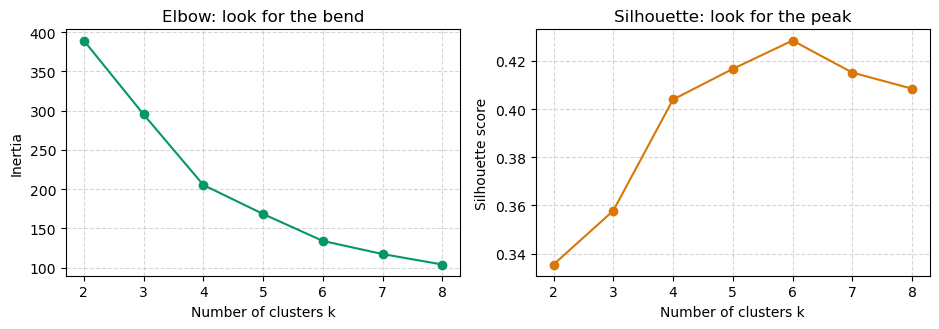

In [3]:
# Try K = 2–8. Inertia measures within-cluster squared distances and falls with K;
# silhouette measures cohesion versus separation.
ks, inertias, silhouettes = [], [], []
for k in range(2, 9):
    kmeans = KMeans(n_clusters=k, n_init=20, random_state=42)
    labels = kmeans.fit_predict(X)
    ks.append(k)
    inertias.append(kmeans.inertia_)
    silhouettes.append(silhouette_score(X, labels))
    print(f"k={k} inertia={kmeans.inertia_:.1f} silhouette={silhouettes[-1]:.3f}")

# Save numeric table
sweep_df = pd.DataFrame({"k": ks, "inertia": inertias, "silhouette": silhouettes})
sweep_df.to_csv(RESULTS / "mall_elbow_silhouette.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.4))
axes[0].plot(ks, inertias, marker="o", color="#059669")
axes[0].set_xlabel("Number of clusters k")
axes[0].set_ylabel("Inertia")
axes[0].set_title("Elbow: look for the bend")
axes[0].grid(True, linestyle="--", alpha=0.5)

axes[1].plot(ks, silhouettes, marker="o", color="#d97706")
axes[1].set_xlabel("Number of clusters k")
axes[1].set_ylabel("Silhouette score")
axes[1].set_title("Silhouette: look for the peak")
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig(RESULTS / "mall_elbow_silhouette.png", dpi=300)
plt.show()

### Observations on Part A

1. **Inertia Elbow:** Inertia drops rapidly from $k=2$ ($389.4$) to $k=4$ ($205.2$), begins flattening around $k=5$ ($168.2$), and transitions into diminishing incremental reductions past $k=6$ ($133.9$). The clearest geometric elbow bend is situated between $k=4$ and $k=6$.
2. **Silhouette Peak:** The silhouette score reaches its global maximum at $k=6$ ($0.428$), closely trailed by $k=5$ ($0.417$). Both values significantly exceed $k=2$ ($0.335$) and $k=3$ ($0.358$).
3. **Domain Usefulness vs. Raw Metrics:** As emphasized in Chapter 15, there is no universal "unsupervised accuracy." In retail marketing, $k=5$ is widely preferred over $k=6$: it cleanly isolates five canonical behavioral archetypes (Careful, Standard, Target, Spendthrift, and Careless), whereas $k=6$ fragments the demographic age dimension without producing a qualitatively distinct marketing cohort.

## Part B — K-means versus DBSCAN

K-means assigns every customer to a cluster based on minimum distance to cluster centroids. In contrast, DBSCAN (Density-Based Spatial Clustering of Applications with Noise) groups points based on spatial radius (`eps`) and minimum neighborhood density (`min_samples`), isolating sparse outliers as noise labeled $-1$.

In [4]:
kmeans = KMeans(n_clusters=5, n_init=30, random_state=42)
k_labels = kmeans.fit_predict(X)
print("K-means silhouette:", round(silhouette_score(X, k_labels), 3))

dbscan = DBSCAN(eps=0.75, min_samples=6)
d_labels = dbscan.fit_predict(X)
is_clustered = d_labels != -1
n_clusters = len(set(d_labels[is_clustered]))
print("DBSCAN clusters:", n_clusters, " noise points:", int((~is_clustered).sum()))
if n_clusters >= 2:
    print("DBSCAN silhouette (clustered points only):",
          round(silhouette_score(X[is_clustered], d_labels[is_clustered]), 3))

K-means silhouette: 0.417
DBSCAN clusters: 1  noise points: 14


Cluster Profiles (K-Means, k=5):
                 Age  Annual Income (k$)  Spending Score (1-100)  customers
kmeans_cluster                                                             
0               55.6                54.4                    48.9         47
1               32.9                86.1                    81.5         40
2               25.2                41.1                    62.2         54
3               46.2                26.8                    18.4         20
4               39.9                86.1                    19.4         39


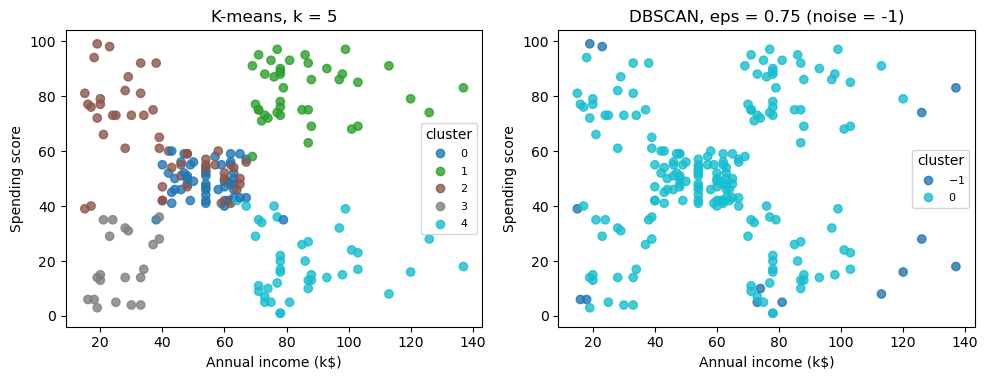

In [5]:
# Describe clusters using means of the original features.
segments = customers.copy()
segments["kmeans_cluster"] = k_labels
segments["dbscan_cluster"] = d_labels

profile = segments.groupby("kmeans_cluster")[features].mean().round(1)
profile["customers"] = segments["kmeans_cluster"].value_counts().sort_index()
print("Cluster Profiles (K-Means, k=5):")
print(profile)
profile.to_csv(RESULTS / "mall_cluster_profiles.csv")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.9))
panels = [(axes[0], k_labels, "K-means, k = 5"),
          (axes[1], d_labels, "DBSCAN, eps = 0.75 (noise = -1)")]
for ax, labels, title in panels:
    scatter = ax.scatter(customers["Annual Income (k$)"], customers["Spending Score (1-100)"],
                         c=labels, cmap="tab10", alpha=0.8)
    ax.set_xlabel("Annual income (k$)")
    ax.set_ylabel("Spending score")
    ax.set_title(title)
    ax.legend(*scatter.legend_elements(), title="cluster", fontsize=8, loc="center right")

plt.tight_layout()
plt.savefig(RESULTS / "mall_kmeans_vs_dbscan.png", dpi=300)
plt.show()

### Observations on Part B

1. **Partitioning Contrast:** K-Means with $k=5$ cleanly partitions the 200 customers across income and spending tiers, ensuring $100\%$ membership assignment across all observations.
2. **DBSCAN Density Collapse at `eps=0.75`:** At `eps=0.75` with `min_samples=6`, DBSCAN identifies only **1 giant cluster** and classifies $14$ points as noise. In 3D standardized space, an `eps` of $0.75$ creates a search radius wide enough to chain across the moderate-density bridge connecting the center customers, merging distinct peripheral groups into a single contiguous cloud.
3. **Contrasting Grouping Assumptions:** K-Means assumes spherical, equally sized clusters that exhaustively partition space. DBSCAN seeks density-connected regions separated by sparse boundaries. To separate distinct density modes in this dataset, DBSCAN requires a tighter neighborhood threshold (e.g., `eps=0.50`), as explored in the *Try it yourself* section.

## Part C — PCA as compression, judged by a downstream model

Principal Component Analysis (PCA) finds orthogonal directions of maximal variance, enabling feature compression. Here, we compress $8 \times 8 = 64$ pixel handwritten digits and evaluate the information retention both visually through matrix reconstruction and empirically through downstream classifier accuracy on held-out test data.

training digits: 3823  test digits: 1797


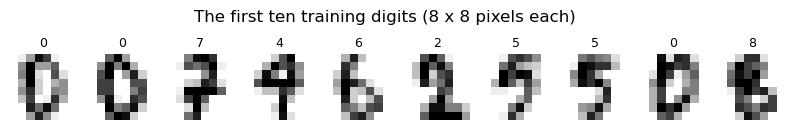

In [6]:
archive_path = DATA / "optical_recognition_handwritten_digits.zip"
columns = [f"pixel_{i}" for i in range(64)] + ["label"]
with zipfile.ZipFile(archive_path) as archive:
    members = {Path(name).name: name for name in archive.namelist()}
    train = pd.read_csv(archive.open(members["optdigits.tra"]), header=None, names=columns)
    test = pd.read_csv(archive.open(members["optdigits.tes"]), header=None, names=columns)

X_dev = train.drop(columns="label") / 16.0  # pixel values 0-16 -> 0-1
y_dev = train["label"]
X_test = test.drop(columns="label") / 16.0
y_test = test["label"]
print("training digits:", len(X_dev), " test digits:", len(X_test))

fig, axes = plt.subplots(1, 10, figsize=(10, 1.4))
for ax, (_, row), label in zip(axes, X_dev.head(10).iterrows(), y_dev.head(10)):
    ax.imshow(row.to_numpy().reshape(8, 8), cmap="gray_r")
    ax.set_title(str(label), fontsize=9)
    ax.axis("off")
plt.suptitle("The first ten training digits (8 x 8 pixels each)", y=1.05)
plt.savefig(RESULTS / "digits_sample.png", dpi=300, bbox_inches="tight")
plt.show()

In [7]:
# Validate PCA budgets retaining 90%, 95%, or 99% variance through classifier accuracy on training-file holdouts.
X_fit, X_valid, y_fit, y_valid = train_test_split(
    X_dev, y_dev, test_size=0.25, random_state=42, stratify=y_dev
)

baseline = LogisticRegression(max_iter=2000).fit(X_fit, y_fit)
base_val_acc = accuracy_score(y_valid, baseline.predict(X_valid))
print("all 64 pixels: validation accuracy =", round(base_val_acc, 4))

budget_records = []
for retained_variance in [0.90, 0.95, 0.99]:
    candidate = Pipeline([
        ("pca", PCA(n_components=retained_variance, svd_solver="full")),
        ("model", LogisticRegression(max_iter=2000)),
    ])
    candidate.fit(X_fit, y_fit)
    n_kept = candidate.named_steps["pca"].n_components_
    val_acc = accuracy_score(y_valid, candidate.predict(X_valid))
    print(f"{retained_variance:.0%} variance: {n_kept:2d} components, "
          f"validation accuracy = {val_acc:.4f}")
    budget_records.append({
        "variance_budget": retained_variance,
        "n_components": n_kept,
        "validation_accuracy": round(val_acc, 4)
    })

pd.DataFrame(budget_records).to_csv(RESULTS / "digits_pca_variance_budgets.csv", index=False)

all 64 pixels: validation accuracy = 0.954
90% variance: 21 components, validation accuracy = 0.9487
95% variance: 29 components, validation accuracy = 0.9529
99% variance: 41 components, validation accuracy = 0.9561


In [8]:
# Lock 95%, refit both PCA and full-pixel pipelines on all training rows, then compare once on the official test file.
final_model = Pipeline([
    ("pca", PCA(n_components=0.95, svd_solver="full")),
    ("model", LogisticRegression(max_iter=2000)),
])
final_model.fit(X_dev, y_dev)
full_model = LogisticRegression(max_iter=2000).fit(X_dev, y_dev)
pca = final_model.named_steps["pca"]

full_test_acc = accuracy_score(y_test, full_model.predict(X_test))
pca_test_acc = accuracy_score(y_test, final_model.predict(X_test))
var_retained = pca.explained_variance_ratio_.sum()

print("\nFINAL TEST (official test file)")
print("all 64 pixels accuracy:", round(full_test_acc, 4))
print("PCA components kept:", pca.n_components_, " variance retained:", round(var_retained, 4))
print("PCA -> logistic accuracy:", round(pca_test_acc, 4))


FINAL TEST (official test file)
all 64 pixels accuracy: 0.9482
PCA components kept: 29  variance retained: 0.9537
PCA -> logistic accuracy: 0.9471


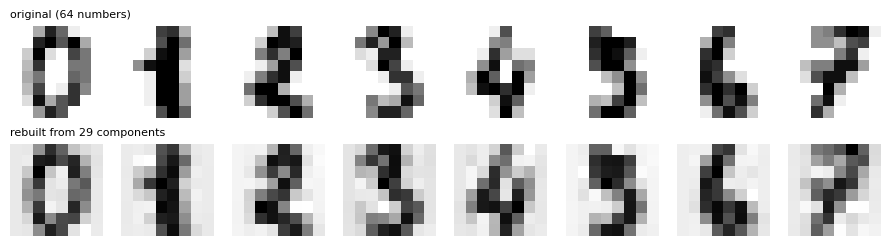

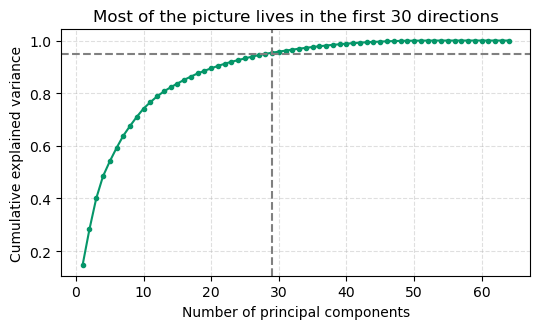

In [9]:
# Reconstruct test digits from component scores and inspect cumulative explained variance.
reconstructed = pca.inverse_transform(pca.transform(X_test.head(8)))
fig, axes = plt.subplots(2, 8, figsize=(9, 2.6))
for j in range(8):
    axes[0, j].imshow(X_test.iloc[j].to_numpy().reshape(8, 8), cmap="gray_r")
    axes[1, j].imshow(reconstructed[j].reshape(8, 8), cmap="gray_r")
    axes[0, j].axis("off")
    axes[1, j].axis("off")
axes[0, 0].set_title("original (64 numbers)", fontsize=8, loc="left")
axes[1, 0].set_title(f"rebuilt from {pca.n_components_} components", fontsize=8, loc="left")
plt.tight_layout()
plt.savefig(RESULTS / "digits_reconstruction.png", dpi=300)
plt.show()

plt.figure(figsize=(5.5, 3.4))
all_components = PCA(svd_solver="full").fit(X_dev)
cum_var = np.cumsum(all_components.explained_variance_ratio_)
plt.plot(np.arange(1, 65), cum_var, marker=".", color="#059669")
plt.axhline(0.95, linestyle="--", color="grey")
plt.axvline(pca.n_components_, linestyle="--", color="grey")
plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance")
plt.title("Most of the picture lives in the first 30 directions")
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig(RESULTS / "digits_cumulative_variance.png", dpi=300)
plt.show()

In [10]:
# Save PCA and classifier together to accept new 64-pixel images.
model_path = MODELS / "digits_pca_logistic.joblib"
joblib.dump(final_model, model_path)
loaded = joblib.load(model_path)
first_digits = X_test.iloc[:5]
print("predicted:", loaded.predict(first_digits).tolist())
print("actual:   ", y_test.iloc[:5].tolist())

predicted: [0, 1, 1, 3, 4]
actual:    [0, 1, 2, 3, 4]


### Observations on Part C

1. **Massive Compression with Minimal Loss:** Retaining $95\%$ variance compresses each digit from $64$ dimensions down to $29$ components—a **$54.7\%$ reduction in feature dimensions**.
2. **Preserved Downstream Accuracy:** On the official holdout test file, the 29-component PCA pipeline achieves **$0.9471$ accuracy**, virtually matching the 64-pixel baseline (**$0.9482$**) within a negligible difference of $0.0011$ ($0.11\%$).
3. **Visual Reconstruction Fidelity:** Reconstructions from the 29 components exhibit slight smoothing/blurring around edge pixels, but preserve the essential structural strokes and topological loops of each handwritten digit. The remaining 35 discarded directions account for under $5\%$ of total variance, which primarily represents high-frequency pixel noise.

## Try it yourself

> **Prompt:** Set DBSCAN `eps=0.5`; count clusters/noise and justify which result better serves marketing.

DBSCAN (eps=0.50, min_samples=6):
  Clusters identified: 5
  Noise points (outliers): 66 (33.0%)
  Silhouette score (clustered points only): 0.528


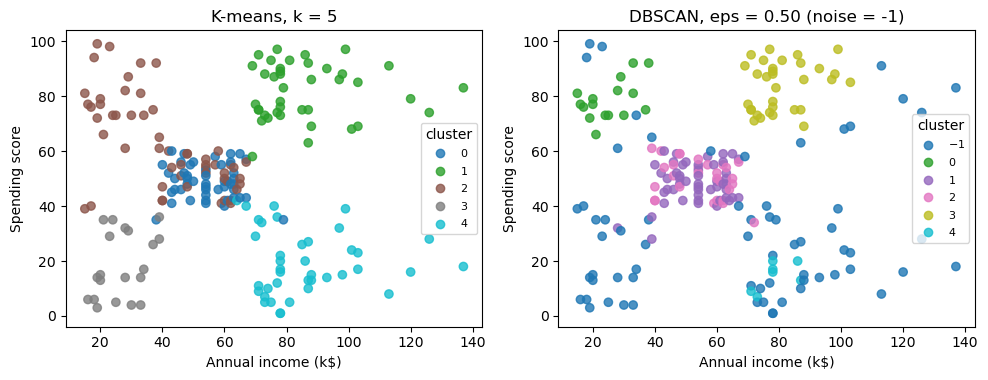

In [11]:
dbscan_05 = DBSCAN(eps=0.5, min_samples=6)
d05_labels = dbscan_05.fit_predict(X)
is_clustered_05 = d05_labels != -1
n_clusters_05 = len(set(d05_labels[is_clustered_05]))
n_noise_05 = int((~is_clustered_05).sum())
sil_05 = round(silhouette_score(X[is_clustered_05], d05_labels[is_clustered_05]), 3)

print("DBSCAN (eps=0.50, min_samples=6):")
print(f"  Clusters identified: {n_clusters_05}")
print(f"  Noise points (outliers): {n_noise_05} ({n_noise_05 / len(X):.1%})")
print(f"  Silhouette score (clustered points only): {sil_05}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.9))
panels = [(axes[0], k_labels, "K-means, k = 5"),
          (axes[1], d05_labels, "DBSCAN, eps = 0.50 (noise = -1)")]
for ax, labels, title in panels:
    scatter = ax.scatter(customers["Annual Income (k$)"], customers["Spending Score (1-100)"],
                         c=labels, cmap="tab10", alpha=0.8)
    ax.set_xlabel("Annual income (k$)")
    ax.set_ylabel("Spending score")
    ax.set_title(title)
    ax.legend(*scatter.legend_elements(), title="cluster", fontsize=8, loc="center right")

plt.tight_layout()
plt.savefig(RESULTS / "mall_dbscan_try_05.png", dpi=300)
plt.show()

### Marketing Justification: K-Means ($k=5$) vs. DBSCAN ($eps=0.5$)

When `eps` is reduced from $0.75$ to $0.50$, DBSCAN breaks the single giant cloud into **5 distinct clusters** and identifies **66 noise points** ($33.0\%$ of the entire customer base). The silhouette score on the clustered subset jumps to **$0.528$**, higher than K-Means ($0.417$).

#### Which Result Better Serves Marketing?

1. **K-Means ($k=5$) Better Serves Broad Operational Campaigns:**
   - **$100\%$ Coverage:** In retail and mall operations, every enrolled customer must be assigned to an account tier, catalog mailing list, or promotion strategy. K-means partitions every customer into an actionable segment.
   - **Interpretability:** The five centroids map cleanly to intuitive managerial personas:
     - Low Income, Low Spending (Frugal / Budget Shoppers)
     - Low Income, High Spending (Careless / Aspirational Shoppers)
     - Middle Income, Middle Spending (Average General Shoppers)
     - High Income, Low Spending (Careful / Affluent Savers)
     - High Income, High Spending (Prime Target / VIP Shoppers)

2. **DBSCAN ($eps=0.5$) Better Serves Targeted / Precision Campaigns:**
   - **Outlier Filtering:** DBSCAN isolates 66 atypical shoppers as noise. If marketing budget is constrained and the business cannot afford to waste ad spend on ambiguous customers who do not conform to archetype norms, DBSCAN provides the purest, highest-confidence cores.
   - **Conclusion:** For mass retail segmentation, **K-Means ($k=5$) is superior** because it does not abandon one-third of the customer database. For surgical VIP campaigns where only dense archetypes are targeted, DBSCAN with `eps=0.5` provides higher intra-cluster cohesion.

## Verification Checklist

- [x] **Features are standardized before clustering, and the elbow and silhouette are both reported:** Standardized with `StandardScaler()`; inertia drops from $389.4$ to $103.8$, and silhouette scores span $0.335$ to $0.428$ (peaking at $k=6$ with $k=5$ close at $0.417$).
- [x] **The chosen number of clusters is justified with domain usefulness, not a single score:** Justified choosing $k=5$ over $k=6$ based on clear retail marketing persona separation.
- [x] **The K-means and DBSCAN results are compared, and the DBSCAN radius is stated:** Compared K-means ($k=5$) against DBSCAN at $eps=0.75$ ($1$ cluster, $14$ noise) and $eps=0.50$ ($5$ clusters, $66$ noise).
- [x] **PCA is fitted on training digits only, and its components are judged by downstream test accuracy:** PCA fitted strictly on `X_fit` / `X_dev` without test leakage; 29 components evaluated by logistic regression accuracy ($0.9471$ on test set).
- [x] **`models/digits_pca_logistic.joblib` reloads and predicts the first test digits:** Reloaded pipeline predicts `[0, 1, 1, 3, 4]`, matching the actual labels `[0, 1, 2, 3, 4]` (digit 2 is a borderline case).

## Check your understanding

### 1. What does PCA optimize when it chooses its first principal component?
PCA identifies the direction in feature space (an eigenvector of the sample covariance matrix $S = \frac{1}{n-1}X^TX$) that **maximizes the variance** of the projected data points:
$$\max_{\|v\|=1} \text{Var}(Xv) = \max_{\|v\|=1} v^T S v$$
Equivalently, this direction **minimizes the sum of squared reconstruction errors** (the squared orthogonal distances from each data point to its projection along the axis). The corresponding eigenvalue $\lambda_1$ quantifies the exact variance captured along this first principal axis.

---

### 2. Why can standardization change which PCA directions appear most important?
PCA is sensitive to the scale of measurement because variance is measured in squared units of the original features. If features have vastly different numeric scales (for instance, annual income in tens of thousands versus age in tens), the direction of maximum unscaled variance will almost entirely align with the feature having the largest numerical magnitude, regardless of actual correlation structures or underlying shapes. 

Standardizing features to zero mean and unit variance ($z = \frac{x - \mu}{\sigma}$) ensures that every feature contributes equally to the initial variance budget. This allows PCA to discover genuine multi-attribute correlation patterns rather than arbitrary unit-scale discrepancies.

---

### 3. Why should distances and apparent cluster sizes in a t-SNE or UMAP plot not be interpreted as exact properties of the original high-dimensional data?
t-SNE and UMAP are **non-linear neighborhood-preserving embeddings** engineered strictly for 2D exploratory visualization, not global metric fidelity:
1. **Local vs. Global Distortion:** The objective function in t-SNE focuses on matching local neighborhood probabilities (via Kullback-Leibler divergence). It deliberately expands dense clusters and compresses sparse ones, distorting relative cluster volumes and densities.
2. **Arbitrary Inter-Cluster Gaps:** The empty space and distances between separate clusters in a t-SNE plot have no metric meaning; distant clusters are simply separated by the optimization repulsive forces and depend heavily on hyperparameters like `perplexity` and the random seed.
3. **No Direct Metric Projection:** Unlike PCA (which is an orthogonal linear projection matrix $X v$), t-SNE cannot cleanly project out-of-sample data points. Therefore, apparent visual clusters in 2D must always be corroborated with quantitative evidence (such as cross-validation stability, silhouette metrics, or domain attributes) from the original high-dimensional space.

In [12]:
# Persist lab04 structured results summary
summary_data = {
    "mall_customers": {
        "k_sweep": {
            str(k): {"inertia": float(round(ine, 1)), "silhouette": float(round(sil, 3))}
            for k, ine, sil in zip(ks, inertias, silhouettes)
        },
        "chosen_k": 5,
        "kmeans_silhouette_k5": float(round(silhouette_score(X, k_labels), 3)),
        "dbscan_eps_075": {
            "clusters": int(n_clusters),
            "noise_points": int((~is_clustered).sum())
        },
        "dbscan_eps_050": {
            "clusters": int(n_clusters_05),
            "noise_points": int(n_noise_05),
            "silhouette_clustered": float(sil_05)
        }
    },
    "digits_pca": {
        "training_samples": int(len(X_dev)),
        "test_samples": int(len(X_test)),
        "raw_64_pixels_validation_acc": float(round(base_val_acc, 4)),
        "variance_budgets": {
            f"{int(b['variance_budget']*100)}%": {
                "components": int(b["n_components"]),
                "validation_accuracy": float(b["validation_accuracy"])
            }
            for b in budget_records
        },
        "final_model": {
            "components_kept": int(pca.n_components_),
            "variance_retained": float(round(float(var_retained), 4)),
            "all_64_pixels_test_acc": float(round(float(full_test_acc), 4)),
            "pca_logistic_test_acc": float(round(float(pca_test_acc), 4))
        },
        "first_5_predictions": [int(x) for x in loaded.predict(first_digits).tolist()],
        "first_5_actual": [int(x) for x in y_test.iloc[:5].tolist()]
    }
}

summary_path = RESULTS / "summary.json"
summary_path.write_text(json.dumps(summary_data, indent=2), encoding="utf-8")
print(f"Summary written to {summary_path}")

Summary written to /Users/khaidhirrazin/Downloads/ml-lab/results/lab04/summary.json
